# TP — Lire et préparer des images réelles (Google Colab)
**IA générative visuelle — IIR**

## Démarrage : seulement ce notebook et le dossier images
1. Ouvrir ce fichier `TPImagesEtudiant.ipynb` dans Google Colab : **Fichier → Importer un notebook**.
2. Exécuter les cellules dans l’ordre, en commençant par l’installation.
3. À l’étape « Importer les images », cliquer sur **Choisir des fichiers**, entrer dans le dossier `images` reçu et sélectionner **les quatre fichiers ensemble** : `astronaut.png`, `coffee.png`, `chelsea.png`, `coffee.jpg` (Ctrl/Cmd pour la sélection multiple).
4. Le notebook range automatiquement ces fichiers dans son dossier de travail. **Aucune archive ZIP n’est à importer dans Colab.**

Les images sont à réimporter si Colab réinitialise la session. Le JPEG est une copie compressée du café PNG, utilisée pour comparer les formats.

Objectif : comparer les lectures, manipuler des pixels, choisir un cadrage et préparer un lot. Aucun GPU nécessaire.

## Installation des bibliothèques

In [1]:
%pip -q install numpy matplotlib pillow opencv-python-headless

## Imports et dossiers de travail

In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import cv2
from google.colab import files

RACINE = Path('/content/TP_Images')
IMAGES = RACINE / 'images'
SORTIES = RACINE / 'sorties'
IMAGES.mkdir(parents=True, exist_ok=True)
SORTIES.mkdir(parents=True, exist_ok=True)

def afficher(images, titres):
    fig, axes = plt.subplots(1, len(images), figsize=(4*len(images), 4), squeeze=False)
    for ax, im, titre in zip(axes[0], images, titres):
        ax.imshow(im)
        ax.set_title(titre)
        ax.axis('off')
    plt.tight_layout()
    plt.show()
print('Bibliothèques importées. Exécuter ensuite la cellule d’importation des images.')


Bibliothèques importées. Exécuter ensuite la cellule d’importation des images.


## Importer les images depuis votre ordinateur
Sélectionner les quatre fichiers à l’intérieur du dossier `images`. Si un fichier manque, relancer cette cellule pour l’ajouter.

In [5]:
# Sélectionner les QUATRE fichiers du dossier images, sans ZIP.
import re

attendus = {'astronaut.png', 'coffee.png', 'chelsea.png', 'coffee.jpg'}
televerses = files.upload()
for nom, contenu in televerses.items():
    nom_simple = Path(nom).name

    # Nettoyer les suffixes automatiques de Colab comme " (1)" ou " (2)"
    nom_nettoye = re.sub(r'\s\(\d+\)\.', '.', nom_simple)

    if nom_nettoye not in attendus:
        print('Fichier ignoré :', nom_simple, '— utiliser les noms originaux du dossier images.')
        continue

    destination = IMAGES / nom_nettoye
    destination.write_bytes(contenu)
    with Image.open(destination) as im:
        im.verify()  # Contrôler que le fichier est réellement une image lisible.

manquants = sorted(nom for nom in attendus if not (IMAGES / nom).is_file())
if manquants:
    raise FileNotFoundError('Images manquantes : ' + ', '.join(manquants)
                            + '. Relancer cette cellule et sélectionner ces fichiers.')
for nom in sorted(attendus):
    with Image.open(IMAGES / nom) as im:
        print(nom, '→ taille (largeur, hauteur) :', im.size, '| mode :', im.mode)
print('Images prêtes ! Passer à l’exercice 1.')

Saving coffee.png to coffee (2).png
Saving coffee.jpg to coffee.jpg
Saving chelsea.png to chelsea (2).png
Saving astronaut.png to astronaut (1).png
astronaut.png → taille (largeur, hauteur) : (512, 512) | mode : RGB
chelsea.png → taille (largeur, hauteur) : (451, 300) | mode : RGB
coffee.jpg → taille (largeur, hauteur) : (600, 400) | mode : RGB
coffee.png → taille (largeur, hauteur) : (600, 400) | mode : RGB
Images prêtes ! Passer à l’exercice 1.


In [6]:
from pathlib import Path
import shutil

attendus = [
    "astronaut.png", "coffee.png",
    "chelsea.png", "coffee.jpg"
]

# Copier les images déjà importées vers le dossier du TP
for nom in attendus:
    source = Path("/content") / nom
    destination = IMAGES / nom

    if source.exists():
        shutil.copy2(source, destination)

    if not destination.exists():
        raise FileNotFoundError(
            f"Importez {nom} avec le bouton d’importation "
            "du panneau Fichiers à gauche."
        )

    with Image.open(destination) as im:
        print(nom, "→", im.size, "| mode :", im.mode)

print("Images prêtes ! Passer à l’exercice 1.")

astronaut.png → (512, 512) | mode : RGB
coffee.png → (600, 400) | mode : RGB
chelsea.png → (451, 300) | mode : RGB
coffee.jpg → (600, 400) | mode : RGB
Images prêtes ! Passer à l’exercice 1.


## 1. Découvrir les fichiers
Une image possède une largeur et une hauteur. Pillow donne (largeur, hauteur), NumPy donne (hauteur, largeur, canaux). Un canal est une grille de valeurs : rouge, vert ou bleu.

**À faire.** Pour chaque PNG, afficher son nom, son mode, sa taille, sa forme NumPy et son type. Afficher les trois photographies.

**Boîte à outils (adapter les variables) :**
```python
Image.open(chemin) ; im.size ; np.array(im).shape
```

Nom : astronaut.png
Mode : RGB
Taille : (512, 512)
Forme NumPy : (512, 512, 3)
Type NumPy : uint8


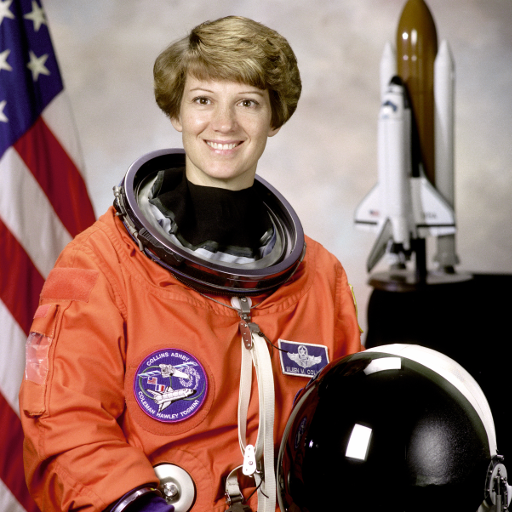

----------------------------------------
Nom : coffee.png
Mode : RGB
Taille : (600, 400)
Forme NumPy : (400, 600, 3)
Type NumPy : uint8


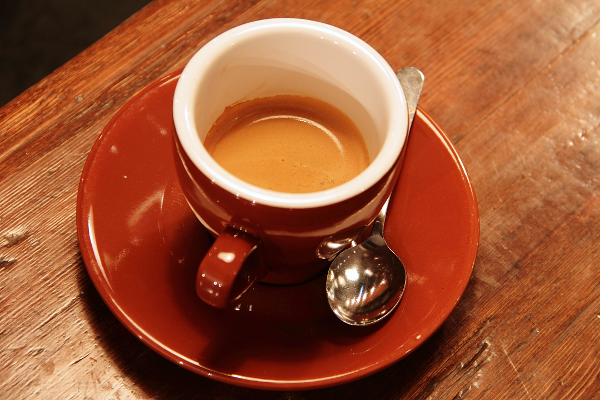

----------------------------------------
Nom : chelsea.png
Mode : RGB
Taille : (451, 300)
Forme NumPy : (300, 451, 3)
Type NumPy : uint8


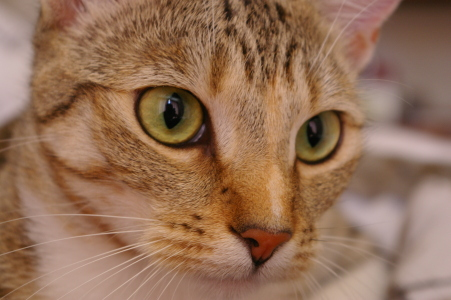

----------------------------------------


In [8]:
# À compléter :
# Pour chaque PNG, afficher son nom, son mode, sa taille, sa forme NumPy et son type. Afficher les trois photographies.

import numpy as np
from PIL import Image
from IPython.display import display

for nom in ["astronaut.png", "coffee.png", "chelsea.png"]:
    im = Image.open(IMAGES / nom)
    arr = np.array(im)

    print("Nom :", nom)
    print("Mode :", im.mode)
    print("Taille :", im.size)
    print("Forme NumPy :", arr.shape)
    print("Type NumPy :", arr.dtype)

    display(im)
    print("-" * 40)



**Vos observations et réponses :**

À compléter:

- **Les trois images montrent que sont en mode RGB. Elles possèdent trois canaux de couleur : rouge, vert et bleu. La taille d’une image avec Pillow est donnée sous la forme (largeur, hauteur), alors que NumPy donne (hauteur, largeur, canaux).**  


---


- **Le type des données est uint8**






## 2. Lire le même PNG de trois façons
Pillow crée un objet image ; on le convertit en tableau. Matplotlib lit directement un tableau. OpenCV lit les couleurs dans l’ordre BGR, alors que Matplotlib affiche du RGB.

**À faire.** Lire coffee.png avec Pillow, Matplotlib et OpenCV. Pour chaque tableau, imprimer shape, dtype, min et max. Afficher les trois lectures sans correction, puis corriger OpenCV.

**Boîte à outils (adapter les variables) :**
```python
np.array(Image.open(chemin).convert("RGB")) ; plt.imread(chemin) ; cv2.imread(str(chemin)) ; cv2.cvtColor(a, cv2.COLOR_BGR2RGB)
```

Lecture : Pillow
Shape : (400, 600, 3)
Dtype : uint8
Min : 0
Max : 255
------------------------------


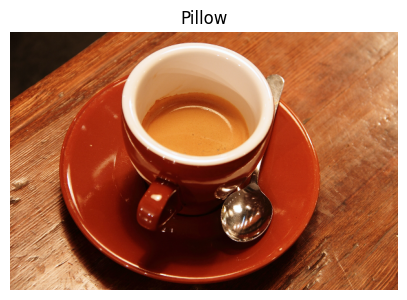

Lecture : Matplotlib
Shape : (400, 600, 3)
Dtype : float32
Min : 0.0
Max : 1.0
------------------------------


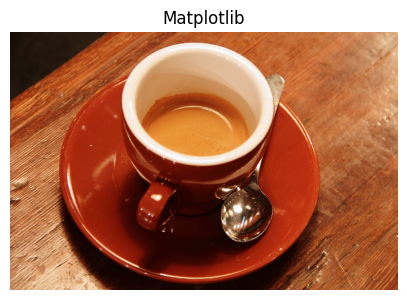

Lecture : OpenCV
Shape : (400, 600, 3)
Dtype : uint8
Min : 0
Max : 255
------------------------------


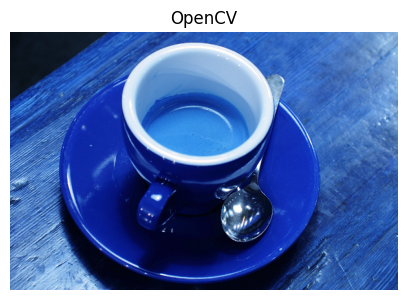

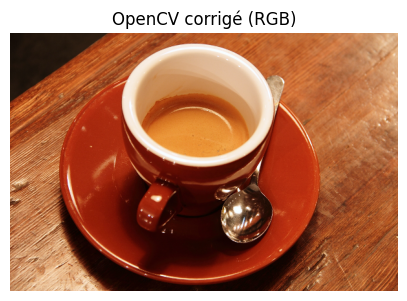

In [9]:
# À compléter :
# Lire coffee.png avec Pillow, Matplotlib et OpenCV. Pour chaque tableau, imprimer shape, dtype, min et max. Afficher les trois lectures sans correction, puis corriger OpenCV.

import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image

chemin = IMAGES / "coffee.png"

# 1. Lecture avec Pillow
img_pil = Image.open(chemin).convert("RGB")
a_pil = np.array(img_pil)

# 2. Lecture avec Matplotlib
a_plt = plt.imread(chemin)

# 3. Lecture avec OpenCV
a_cv = cv2.imread(str(chemin))

# Afficher les informations et les images
lectures = [
    ("Pillow", a_pil),
    ("Matplotlib", a_plt),
    ("OpenCV", a_cv)
]

for nom, a in lectures:
    print("Lecture :", nom)
    print("Shape :", a.shape)
    print("Dtype :", a.dtype)
    print("Min :", a.min())
    print("Max :", a.max())
    print("-" * 30)

    plt.figure(figsize=(5, 4))
    plt.imshow(a)
    plt.title(nom)
    plt.axis("off")
    plt.show()

# Correction de l'ordre des couleurs OpenCV : BGR vers RGB
a_cv_rgb = cv2.cvtColor(a_cv, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(5, 4))
plt.imshow(a_cv_rgb)
plt.title("OpenCV corrigé (RGB)")
plt.axis("off")
plt.show()



**Vos observations et réponses :**

À compléter.
- **Les trois méthodes donnent la même forme (400, 600, 3). Pillow et OpenCV utilisent le type uint8 avec des valeurs entre 0 et 255, tandis que Matplotlib utilise float32 avec des valeurs entre 0 et 1.**
- **OpenCV utilise l’ordre BGR, contrairement à Pillow et Matplotlib qui utilisent RGB. Il faut convertir BGR en RGB pour afficher correctement les couleurs.**

## 3. PNG et JPEG : ne pas généraliser
Le JPEG fourni est une copie compressée du même café. Comparer les méthodes sur un même fichier, puis comparer les formats séparément.

**À faire.** Lire coffee.jpg avec Matplotlib. Comparer son type au PNG. Mesurer la différence moyenne entre la copie JPEG et le PNG original.

**Boîte à outils (adapter les variables) :**
```python
a.astype(np.float32) ; np.abs(a-b).mean()
```

In [10]:
# À compléter :
# Lire coffee.jpg avec Matplotlib. Comparer son type au PNG. Mesurer la différence moyenne entre la copie JPEG et le PNG original.

import numpy as np
import matplotlib.pyplot as plt

chemin_png = IMAGES / "coffee.png"
chemin_jpg = IMAGES / "coffee.jpg"

# Lire les deux images avec Matplotlib
img_png = plt.imread(chemin_png)
img_jpg = plt.imread(chemin_jpg)

# Afficher les informations
print("PNG")
print("Shape :", img_png.shape)
print("Dtype :", img_png.dtype)
print("Min :", img_png.min())
print("Max :", img_png.max())

print("\nJPEG")
print("Shape :", img_jpg.shape)
print("Dtype :", img_jpg.dtype)
print("Min :", img_jpg.min())
print("Max :", img_jpg.max())

# Comparer les deux images
png_float = img_png.astype(np.float32)
jpg_float = img_jpg.astype(np.float32)

difference = np.abs(png_float - jpg_float)

print("\nDifférence moyenne :", difference.mean())



PNG
Shape : (400, 600, 3)
Dtype : float32
Min : 0.0
Max : 1.0

JPEG
Shape : (400, 600, 3)
Dtype : uint8
Min : 0
Max : 255

Différence moyenne : 98.23678


**Vos observations et réponses :**

À compléter.

**Le PNG et le JPEG ont la même forme (400, 600, 3), mais leurs types de données
sont différents. Le PNG utilise float32 avec des valeurs entre 0 et 1, tandis que le JPEG utilise uint8 avec des valeurs entre 0 et 255. La différence moyenne obtenue est de 98.23678.**



## 4. Explorer les pixels et les canaux
a[y,x] désigne la ligne y puis la colonne x. Une couleur RGB contient trois nombres. Un canal isolé est une image 2D.

**À faire.** Afficher un pixel, isoler R/G/B puis convertir le café en niveaux de gris. Afficher avec cmap="gray".

**Boîte à outils (adapter les variables) :**
```python
a[y,x] ; a[:,:,0] ; cv2.cvtColor(a, cv2.COLOR_RGB2GRAY)
```

Pixel [y, x] : [139  50  18]


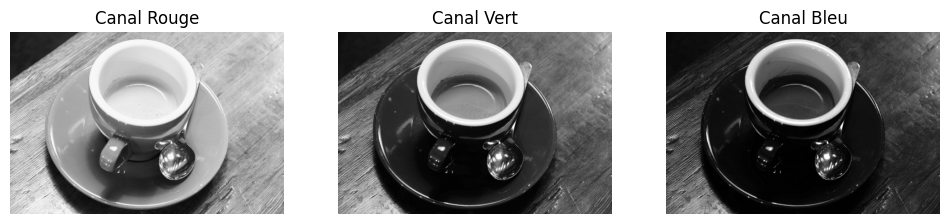

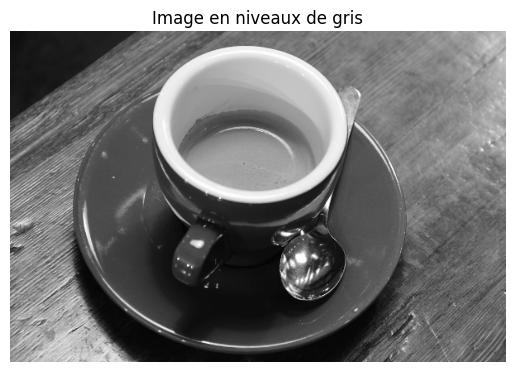

In [11]:
# À compléter :
# Afficher un pixel, isoler R/G/B puis convertir le café en niveaux de gris. Afficher avec cmap="gray".

import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image

# Lire l'image du café en RGB
chemin = IMAGES / "coffee.png"
img = Image.open(chemin).convert("RGB")
a = np.array(img)

# 1. Afficher la valeur d'un pixel
y, x = 100, 100
print("Pixel [y, x] :", a[y, x])

# 2. Isoler les trois canaux R, G et B
rouge = a[:, :, 0]
vert = a[:, :, 1]
bleu = a[:, :, 2]

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(rouge, cmap="gray")
plt.title("Canal Rouge")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(vert, cmap="gray")
plt.title("Canal Vert")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(bleu, cmap="gray")
plt.title("Canal Bleu")
plt.axis("off")

plt.show()

# 3. Convertir l'image en niveaux de gris
gris = cv2.cvtColor(a, cv2.COLOR_RGB2GRAY)

plt.imshow(gris, cmap="gray")
plt.title("Image en niveaux de gris")
plt.axis("off")
plt.show()


**Vos observations et réponses :**

À compléter.

**Un pixel RGB contient trois valeurs : rouge, vert et bleu. Chaque canal peut être affiché séparément en niveaux de gris. La conversion en niveaux de gris transforme l’image couleur en une image avec une seule valeur par pixel.**

## 5. Recadrer et manipuler
Un recadrage sélectionne une région, sans inventer de nouveaux pixels. Les indices sont [début:fin], avec la fin exclue. Une augmentation produit une variante pour l’apprentissage ; elle doit rester pertinente pour les données.

**À faire.** Extraire lignes 80 à 319 et colonnes 150 à 449. Retourner horizontalement. Augmenter légèrement la luminosité.

**Boîte à outils (adapter les variables) :**
```python
a[80:320,150:450] ; np.fliplr(a) ; np.clip(a.astype(np.float32)*1.2,0,255)
```

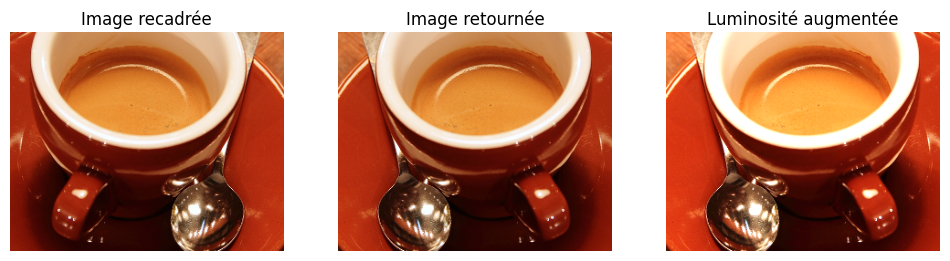

Taille originale : (400, 600, 3)
Taille recadrée : (240, 300, 3)


In [12]:
# À compléter :
# Extraire lignes 80 à 319 et colonnes 150 à 449. Retourner horizontalement. Augmenter légèrement la luminosité.

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Lire l'image
img = Image.open(IMAGES / "coffee.png").convert("RGB")
a = np.array(img)

# 1. Recadrer : lignes 80 à 319 et colonnes 150 à 449
recadree = a[80:320, 150:450]

# 2. Retourner horizontalement
retournee = np.fliplr(recadree)

# 3. Augmenter légèrement la luminosité
lumineuse = np.clip(retournee.astype(np.float32) * 1.2, 0, 255).astype(np.uint8)

# Afficher les trois résultats
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(recadree)
plt.title("Image recadrée")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(retournee)
plt.title("Image retournée")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(lumineuse)
plt.title("Luminosité augmentée")
plt.axis("off")

plt.show()

print("Taille originale :", a.shape)
print("Taille recadrée :", recadree.shape)


**Vos observations et réponses :**

À compléter.

- **Le recadrage sélectionne une partie de l’image sans créer de nouveaux pixels. Le retournement horizontal inverse l’image de gauche à droite. L’augmentation de la luminosité rend l’image plus claire:**

**-La taille de l’image recadrée est (240, 300, 3).**

## 6. Trois stratégies de redimensionnement
Un modèle attend souvent une taille précise. Étirement : change les proportions. Recadrage centré : remplit le carré mais retire du contenu. Marges : conserve le cadrage et ajoute des bordures. La taille 256×256 est choisie pour ce TP ; vérifier celle du modèle réel.

**À faire.** À partir du café, créer les trois versions en 256×256. Afficher entrée et résultats. Tester ensuite sur le chat.

**Boîte à outils (adapter les variables) :**
```python
im.resize((256,256), Image.Resampling.BILINEAR) ; ImageOps.fit(im,(256,256)) ; ImageOps.pad(im,(256,256),color=(0,0,0))
```

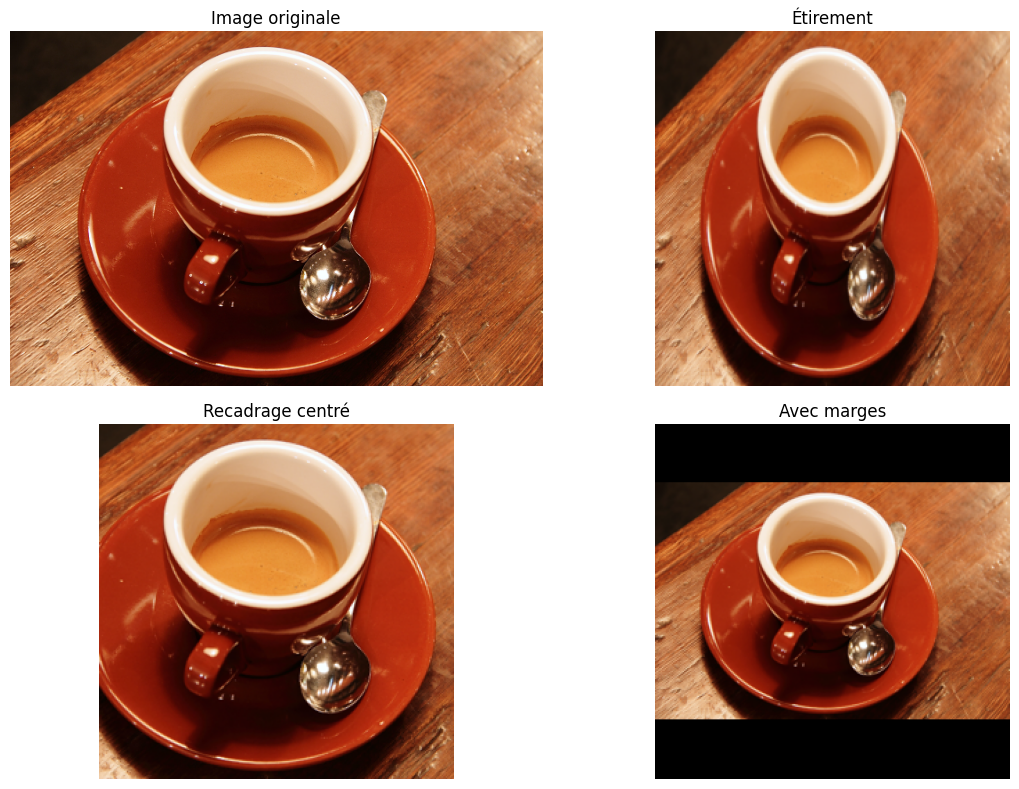

Image originale : (600, 400)
Étirement : (256, 256)
Recadrage centré : (256, 256)
Avec marges : (256, 256)


In [13]:
# À compléter :
# À partir du café, créer les trois versions en 256×256. Afficher entrée et résultats. Tester ensuite sur le chat.


from PIL import Image, ImageOps
import matplotlib.pyplot as plt

# Image originale
img = Image.open(IMAGES / "coffee.png").convert("RGB")

# 1. Étirement
etirement = img.resize((256, 256), Image.Resampling.BILINEAR)

# 2. Recadrage centré
recadrage = ImageOps.fit(img, (256, 256))

# 3. Ajout de marges noires
marges = ImageOps.pad(img, (256, 256), color=(0, 0, 0))

# Afficher l'image originale et les trois résultats
images = [
    ("Image originale", img),
    ("Étirement", etirement),
    ("Recadrage centré", recadrage),
    ("Avec marges", marges)
]

plt.figure(figsize=(12, 8))

for i, (titre, image) in enumerate(images, 1):
    plt.subplot(2, 2, i)
    plt.imshow(image)
    plt.title(titre)
    plt.axis("off")

plt.tight_layout()
plt.show()

# Vérifier les dimensions
for titre, image in images:
    print(titre, ":", image.size)


**Vos observations et réponses :**

À compléter.

 - **Les trois méthodes donnent une image de taille 256 × 256 pixels. L’étirement modifie les proportions de l’image. Le recadrage centré conserve les proportions, mais supprime une partie du contenu. L’ajout de marges conserve le contenu principal et ajoute des bordures noires.**

## 7. Normaliser et revenir à une image affichable
Normaliser change l’échelle des valeurs, pas le contenu visuel. Les conventions 0–1 et −1–1 sont fréquentes ; le modèle impose sa convention. Ne pas diviser une seconde fois un tableau déjà entre 0 et 1.

**À faire.** Convertir la version avec marges en float32 entre 0 et 1, puis entre −1 et 1. Inverser la transformation pour afficher.

**Boîte à outils (adapter les variables) :**
```python
a.astype(np.float32)/255.0 ; x*2-1 ; (x+1)/2
```

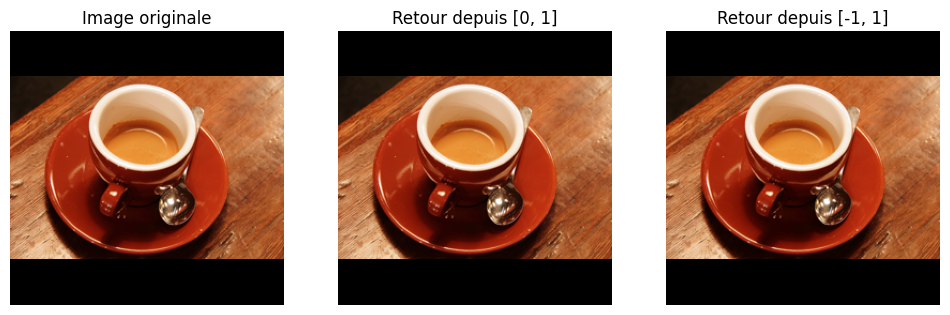

Image originale : 0.0 255.0
Normalisée [0, 1] : 0.0 1.0
Normalisée [-1, 1] : -1.0 1.0


In [14]:
# À compléter :
# Convertir la version avec marges en float32 entre 0 et 1, puis entre −1 et 1. Inverser la transformation pour afficher.


import numpy as np
import matplotlib.pyplot as plt

# Image avec marges créée dans l'exercice 6
a = np.array(marges).astype(np.float32)

# 1. Normalisation entre 0 et 1
image_01 = a / 255.0

# 2. Normalisation entre -1 et 1
image_m11 = image_01 * 2 - 1

# 3. Revenir à l'échelle originale [0, 255]
retour_01 = image_01 * 255.0
retour_m11 = ((image_m11 + 1) / 2) * 255.0

# Afficher les images
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(a.astype(np.uint8))
plt.title("Image originale")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(retour_01.astype(np.uint8))
plt.title("Retour depuis [0, 1]")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(retour_m11.astype(np.uint8))
plt.title("Retour depuis [-1, 1]")
plt.axis("off")

plt.show()

print("Image originale :", a.min(), a.max())
print("Normalisée [0, 1] :", image_01.min(), image_01.max())
print("Normalisée [-1, 1] :", image_m11.min(), image_m11.max())


**Vos observations et réponses :**

À compléter.

- **La normalisation change l’échelle des valeurs des pixels sans modifier le contenu visuel. Les valeurs sont comprises entre 0 et 1, ou entre -1 et 1 selon la méthode utilisée. En inversant la transformation, on retrouve une image affichable similaire à l’image originale.**

## 8. Construire un lot prêt pour un modèle
Un lot (batch) regroupe plusieurs images. NHWC signifie nombre, hauteur, largeur, canaux. NCHW signifie nombre, canaux, hauteur, largeur. La convention dépend de l’outil et du modèle.

**À faire.** Écrire une fonction qui ouvre une image, la convertit en RGB, ajoute des marges en 256×256 et normalise entre 0 et 1. Empiler les trois images puis passer de NHWC à NCHW.

**Boîte à outils (adapter les variables) :**
```python
np.stack(liste) ; np.transpose(batch,(0,3,1,2)) ; np.isfinite(batch).all()
```

In [15]:
# À compléter :
# Écrire une fonction qui ouvre une image, la convertit en RGB, ajoute des marges en 256×256 et normalise entre 0 et 1. Empiler les trois images puis passer de NHWC à NCHW.


import numpy as np
from PIL import Image, ImageOps

# Fonction de préparation d'une image
def preparer_image(chemin):
    img = Image.open(chemin).convert("RGB")

    # Redimensionner avec des marges en 256 × 256
    img = ImageOps.pad(img, (256, 256), color=(0, 0, 0))

    # Normaliser entre 0 et 1
    a = np.array(img).astype(np.float32) / 255.0

    return a

# Préparer les trois images
liste = [
    preparer_image(IMAGES / "astronaut.png"),
    preparer_image(IMAGES / "coffee.png"),
    preparer_image(IMAGES / "chelsea.png")
]

# Empiler les images : NHWC
batch = np.stack(liste)

print("Shape NHWC :", batch.shape)
print("Dtype :", batch.dtype)
print("Valeurs min :", batch.min())
print("Valeurs max :", batch.max())
print("Toutes les valeurs sont finies :", np.isfinite(batch).all())

# Passer de NHWC à NCHW
batch_nchw = np.transpose(batch, (0, 3, 1, 2))

print("Shape NCHW :", batch_nchw.shape)



Shape NHWC : (3, 256, 256, 3)
Dtype : float32
Valeurs min : 0.0
Valeurs max : 1.0
Toutes les valeurs sont finies : True
Shape NCHW : (3, 3, 256, 256)


**Vos observations et réponses :**

À compléter.

**Les trois images sont préparées en RGB, redimensionnées en 256 × 256 et normalisées entre 0 et 1. Elles sont regroupées dans un batch de forme (3, 256, 256, 3) au format NHWC. La transposition permet d’obtenir le format NCHW : (3, 3, 256, 256).**

## 9. Sauvegarder et relire
Une image enregistrée doit retrouver les bonnes couleurs. OpenCV attend BGR pour écrire un fichier couleur. Le PNG permet ici une vérification exacte des pixels.

**À faire.** Enregistrer la version préparée avec Pillow puis avec OpenCV. Relire et comparer.

**Boîte à outils (adapter les variables) :**
```python
Image.fromarray(a).save(chemin) ; cv2.imwrite(str(chemin),bgr)
```

Pillow :
Shape : (256, 256, 3)
Pixels identiques : True

OpenCV :
Shape : (256, 256, 3)
Pixels identiques : True


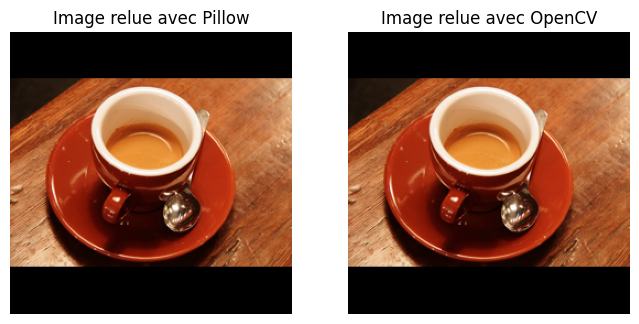

In [16]:
# À compléter :
# Enregistrer la version préparée avec Pillow puis avec OpenCV. Relire et comparer.


import numpy as np
import cv2
from PIL import Image

# Utiliser l'image préparée avec marges de l'exercice 6
a = np.array(marges).astype(np.uint8)

# 1. Enregistrer avec Pillow
chemin_pillow = "/content/cafe_pillow.png"
Image.fromarray(a).save(chemin_pillow)

# Relire avec Pillow
relu_pillow = np.array(Image.open(chemin_pillow).convert("RGB"))

# 2. Enregistrer avec OpenCV
chemin_opencv = "/content/cafe_opencv.png"
bgr = cv2.cvtColor(a, cv2.COLOR_RGB2BGR)
cv2.imwrite(chemin_opencv, bgr)

# Relire avec OpenCV et convertir en RGB
relu_opencv = cv2.imread(chemin_opencv)
relu_opencv = cv2.cvtColor(relu_opencv, cv2.COLOR_BGR2RGB)

# 3. Comparer les résultats
print("Pillow :")
print("Shape :", relu_pillow.shape)
print("Pixels identiques :", np.array_equal(a, relu_pillow))

print("\nOpenCV :")
print("Shape :", relu_opencv.shape)
print("Pixels identiques :", np.array_equal(a, relu_opencv))

# Afficher les images relues
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(relu_pillow)
plt.title("Image relue avec Pillow")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(relu_opencv)
plt.title("Image relue avec OpenCV")
plt.axis("off")

plt.show()



**Vos observations et réponses :**

À compléter.

**Les deux méthodes permettent d’enregistrer et de relire l’image sans modifier les pixels. Avec Pillow, les couleurs sont conservées directement. Avec OpenCV, il faut convertir l’image de RGB en BGR avant l’enregistrement, puis de BGR en RGB après la lecture. Les deux comparaisons donnent True, ce qui confirme que les pixels sont identiques à l’image originale.**